# Finding mixed failure modes in equipment lifetimes

I built this notebook because my Reliability page can mislead when one sample mixes two kinds of failure.
Some bearings wear out late. Others fail early after installation, usually because of
dirt or a poor fit. A single Weibull curve fitted to the whole sample can describe
neither group well. Here I look for groups with scikit-learn, fit a curve to each group
and compare it with the pooled fit. Then I test whether install-time readings can flag
early failures.

The records below are **invented** so the notebook runs anywhere and every number can be
checked. To use real records, replace `generate_records()` with a CSV that has the columns
`time` (hours), `failed` (1 = failed, 0 = still running at that time), `load` and
`contamination`. The code in `failure_modes.py` does the rest.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score
from sklearn.calibration import calibration_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import failure_modes as fm

pd.set_option("display.width", 120)
print("Seed:", fm.SEED)

Seed: 20261110


## 1. The records

Each row is one bearing. A `failed` value of 0 means the bearing was still running when it was
last checked, so its true life is longer than `time`. Ignoring those rows would make the
bearings look worse than they are. The `invented_mode` column is the answer key I used to
generate the data. A real sample does not have one.

In [2]:
records = fm.generate_records()
print(f"{len(records)} bearings, {records['failed'].sum()} failures, "
      f"{(records['failed'] == 0).sum()} still running at their last check")
records.head()

600 bearings, 325 failures, 275 still running at their last check


,unit_id,time,failed,load,contamination,invented_mode
0,BRG-001,1715.04,0,0.427,0.310,wear
1,BRG-002,203.90,1,0.660,0.723,early
2,BRG-003,2763.43,0,0.638,0.638,wear
3,BRG-004,1979.46,1,0.472,0.415,wear
4,BRG-005,1582.56,0,0.889,0.867,wear


## 2. Choosing the number of groups

I scale four columns so none dominates distance: the log of life (log spreads long
lives out evenly), whether the bearing was still running, the load and the contamination
reading. Then I try 2, 3 and 4 groups two ways:

- **K-means** asks how tight each group is. A higher silhouette score (from -1 to 1) means
  better separated groups.
- **Gaussian mixture** asks which set of overlapping bell-shaped groups explains the data
  best. A lower BIC means a better fit after penalising extra parameters.

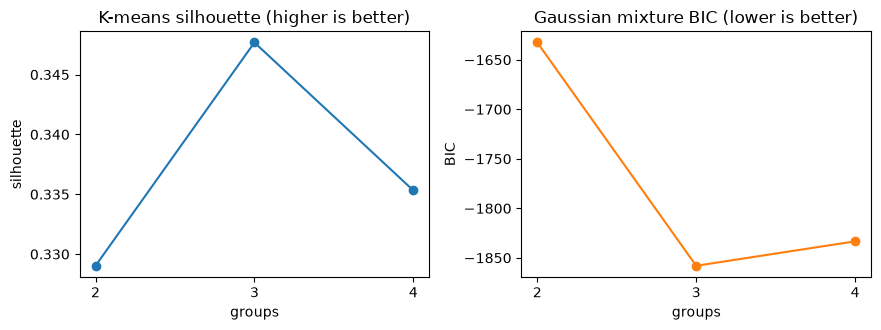

K-means silhouette picks 3 groups
Gaussian mixture BIC picks 3 groups


In [3]:
features, scaler = fm.clustering_features(records)
kmeans_scan = fm.scan_kmeans(features)
mixture_scan = fm.scan_gaussian_mixture(features)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))
left.plot(kmeans_scan["clusters"], kmeans_scan["silhouette"], marker="o")
left.set(title="K-means silhouette (higher is better)", xlabel="groups", ylabel="silhouette", xticks=fm.CANDIDATE_COUNTS)
right.plot(mixture_scan["clusters"], mixture_scan["bic"], marker="o", color="tab:orange")
right.set(title="Gaussian mixture BIC (lower is better)", xlabel="groups", ylabel="BIC", xticks=fm.CANDIDATE_COUNTS)
fig.tight_layout()
plt.show()

k_silhouette = fm.best_by(kmeans_scan, "silhouette", maximise=True)
k_bic = fm.best_by(mixture_scan, "bic", maximise=False)
print("K-means silhouette picks", k_silhouette, "groups")
print("Gaussian mixture BIC picks", k_bic, "groups")

When both criteria agree, I use that count. When they disagree, I would check the fits
below for each option before trusting either one. Here I keep the count they both chose.

In [4]:
assert k_silhouette == k_bic, "the two criteria disagree; compare fits before choosing"
chosen = int(k_silhouette)
labels = kmeans_scan.loc[kmeans_scan["clusters"] == chosen, "labels"].iloc[0]
agreement = adjusted_rand_score(labels, mixture_scan.loc[mixture_scan["clusters"] == chosen, "labels"].iloc[0])
print(f"Groups: {chosen}. Agreement between K-means and the mixture model (adjusted Rand, 1 = identical): {agreement:.2f}")
print()
print(pd.crosstab(records["invented_mode"], pd.Series(labels, name="group"), margins=True))

Groups: 3. Agreement between K-means and the mixture model (adjusted Rand, 1 = identical): 0.91

group           0    1    2  All
invented_mode                   
early          94   19   77  190
wear            3  256  151  410
All            97  275  228  600


The crosstab compares each group with the answer key. Group 0 is mostly early-failure bearings
(94 of 97). Group 2 is mostly wear-out, but 77 early-failure bearings land there too.
Group 1 holds only bearings still running at their last check, 19 of them early-failure
bearings checked before they failed. This is the censoring problem: the groups are a useful
first split, not a clean answer, which is why I check the fits next.

## 3. A Weibull curve for each group

A Weibull curve has two numbers. The shape says whether the failure rate rises with age
(above 1) or falls (below 1). The scale says roughly when about 63% of units have failed.
I use the `fit_life_model` function from `reliability.py`, which keeps the still-running
bearings in the fit as suspensions. A group with no failures cannot give a Weibull fit,
so it is reported instead of guessed.

In [5]:
curves = fm.weibull_by_cluster(records, labels)
curves.round(3)

,group,units,failures,shape,scale,b10,note
0,pooled,600,325,0.800,2015.632,120.806,
1,cluster 0,97,97,0.712,86.601,3.667,
2,cluster 1,275,0,NaN,NaN,NaN,No observed failures: finite mean life cannot ...
3,cluster 2,228,228,1.718,1312.432,354.060,


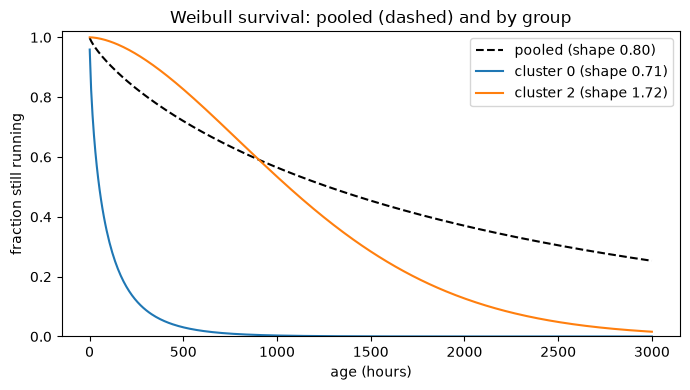

In [6]:
times = np.linspace(1, 3000, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for row in curves.itertuples():
    if np.isnan(row.shape):
        continue
    survival = np.exp(-(times / row.scale) ** row.shape)
    style = {"linestyle": "--", "color": "black"} if row.group == "pooled" else {}
    ax.plot(times, survival, label=f"{row.group} (shape {row.shape:.2f})", **style)
ax.set(xlabel="age (hours)", ylabel="fraction still running", title="Weibull survival: pooled (dashed) and by group", ylim=(0, 1.02))
ax.legend()
fig.tight_layout()
plt.show()

The pooled curve mixes the two failure modes, so its shape falls between them and describes
neither group. The group curves are closer to the process that made them. A group with
no failures shows up in the table, which is a result in itself: those bearings are mostly
survivors, and they should not be read as a third failure mode.

## 4. Predicting early failure from install-time readings

Now a practical question: can I flag early failures from readings taken at installation?
I define an early failure as a failure before 300 hours. A bearing still running at 200 hours
could still fail early, so I drop it from this test rather than guess. Age and groups come
from the failure itself, so I do not use them as inputs. The only inputs are `load` and
`contamination`.

I compare logistic regression and a random forest, both with 5-fold cross-validation.
Each bearing is scored by a model that never saw it. A prevalence-only model, which always
predicts the average rate, gives the baseline to beat.

In [7]:
features_early, early = fm.early_failure_dataset(records)
print(f"{len(early)} bearings usable, {early.sum()} early failures ({early.mean():.1%})")
results = fm.cross_validated_baselines(features_early, early)
summary = pd.DataFrame({
    name: {"ROC AUC (1 = perfect, 0.5 = chance)": r["auc"], "Brier score (lower is better)": r["brier"]}
    for name, r in results.items()
}).T
summary.round(3)

580 bearings usable, 114 early failures (19.7%)


,"ROC AUC (1 = perfect, 0.5 = chance)",Brier score (lower is better)
prevalence only,0.496,0.158
logistic regression,0.748,0.135
random forest,0.748,0.138


The confusion matrix counts predictions at a 0.5 cutoff. Rows are what happened, columns
are what the model predicted. The calibration plot asks a different question: when a model
says 30%, does about 30% of that group fail early? Points on the dashed diagonal mean
the probabilities can be taken at face value.

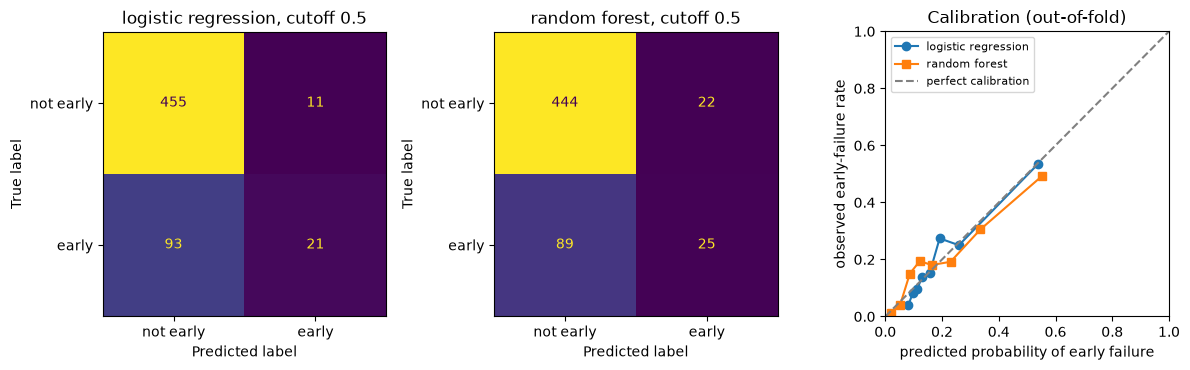

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

names = ["logistic regression", "random forest"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name in zip(axes[:2], names):
    ConfusionMatrixDisplay(results[name]["confusion"], display_labels=["not early", "early"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}, cutoff 0.5")
for name, style in zip(names, ["o-", "s-"]):
    observed, predicted = calibration_curve(early, results[name]["probability"], n_bins=8, strategy="quantile")
    axes[2].plot(predicted, observed, style, label=name)
axes[2].plot([0, 1], [0, 1], "--", color="grey", label="perfect calibration")
axes[2].set(xlabel="predicted probability of early failure", ylabel="observed early-failure rate",
            title="Calibration (out-of-fold)", xlim=(0, 1), ylim=(0, 1))
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

At a 0.5 cutoff the models flag few bearings, because early failures are the minority.
Their ranking is still much better than the prevalence-only reference, which is the
point of the AUC column. At that cutoff they catch under a quarter of early failures
(21 and 25 of 114). If I need more early failures caught, I would lower the cutoff
and accept more false alarms, and I would check the calibration plot before using the
probabilities as risk numbers.

## 5. Checks and limits

These checks stop the notebook if a result moves outside the range I expect from this seed.

In [9]:
assert len(labels) == len(records)
assert summary.loc["logistic regression", "ROC AUC (1 = perfect, 0.5 = chance)"] > summary.loc["prevalence only", "ROC AUC (1 = perfect, 0.5 = chance)"] + .15
assert curves.iloc[0]["group"] == "pooled"
print("All checks passed.")

All checks passed.


**Limits.** Groups found by clustering are a hypothesis, not proof of two causes. Censored
bearings are placed by their last-check age, which can pull them into the wrong group.
The early-failure test uses 300 hours as the cutoff, which I chose for this invented
process. The results come from one seeded sample. Test a real record set with the same
cutoff, and check the fitted curves against the engineering history before acting on them.